In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [2]:
import matplotlib.pyplot as plt
from core.kmeans import cluster_points, kmeans_cluster, kmeans_fit
import numpy as np
import kagglehub
import pandas as pd

np.random.seed(42)

In [3]:
colors = [
    "blue",
    "green",
    "purple",
    "orange",
    "cyan",
    "magenta",
    "yellow",
    "black",
    "pink"
]

#### Dataset ophalen en inladen

In [4]:
path = kagglehub.dataset_download("arshid/iris-flower-dataset")
file_path = os.path.join(path, 'IRIS.csv')

iris = pd.read_csv(file_path)
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Enkele iteratie KMeans

De stappen die in een enkele iteratie van het KMeans algoritme zitten. (Voor 2 gekozen features: 'petal_length' en 'sepal_width').

#### De data 

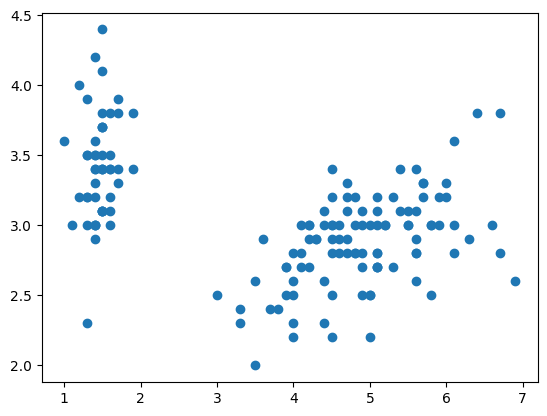

In [5]:
X = iris[["petal_length", "sepal_width"]].to_numpy()
plt.scatter(X[:,0], X[:, 1])
plt.show()

#### Centroids initialiseren

Het aantal centroids is hier gelijk aan het aantal categorieën van de dataset. Deze centroids worden willekeurig geïnitialiseerd.

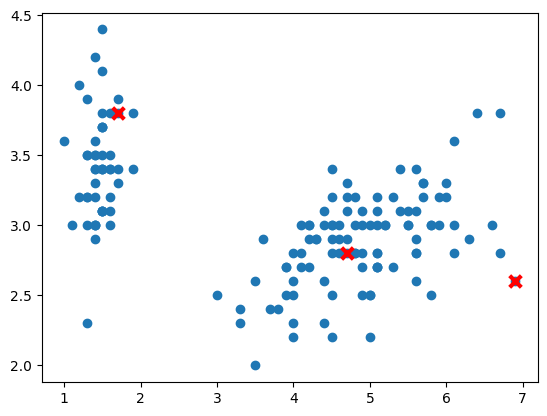

In [6]:
# Aantal centroids = aantal categorieën.
num_centroids = len(iris["species"].unique())

# Centroids zijn num_centroids aantal willekeurig gekozen punten uit de dataset.
indices = np.random.permutation(X.shape[0])[:num_centroids]
centroids = X[indices]

plt.scatter(X[:, 0], X[:, 1])
plt.scatter(centroids[:,0], centroids[:, 1], c="red", marker="x", s=70, linewidths=3)
plt.show()

#### Punten labelen

Elk punt in de dataset wordt gelabeld op basis van de kortste afstand tot een centroid.

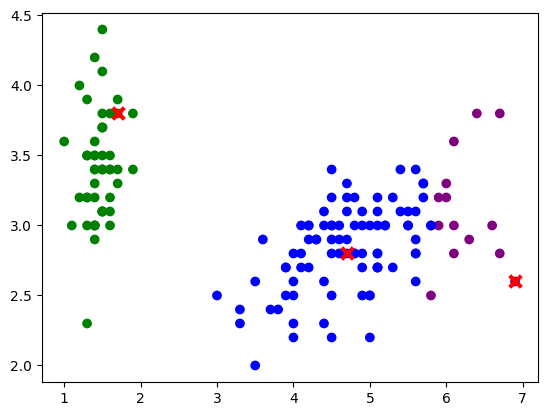

In [7]:
labels = cluster_points(X, centroids)
point_colors = [colors[label] for label in labels]

plt.scatter(X[:, 0], X[:, 1], c=point_colors)
plt.scatter(centroids[:,0], centroids[:, 1], c="red", marker="x", s=70, linewidths=3)
plt.show()

#### Herhalen

Na het labelen wordt een nieuwe centroid berekend (gemiddelde van bijbehorende cluster), waarna de punten opnieuw gelabeld worden bij de nieuwe centroid. Dit wordt herhaald tot de centroids niet meer veranderen. 

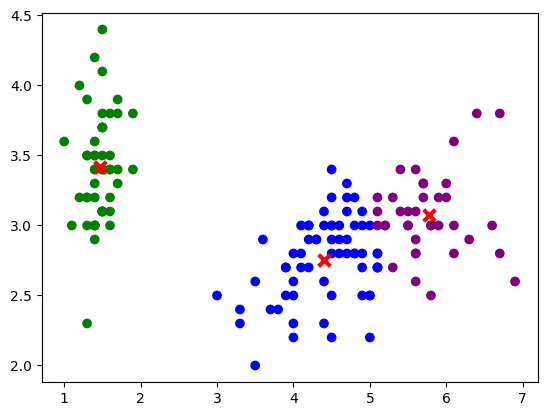

In [8]:
clusters, centroids = kmeans_cluster(X, num_centroids, centroids)
color_mappings = [
    colors[i]
    for i in range(len(clusters))
    for _ in range(len(clusters[i]))
]
points = np.array([p for cluster in clusters for p in cluster])

plt.scatter(points[:,0], points[:, 1], c=color_mappings)
plt.scatter(centroids[:,0], centroids[:, 1], c="red", marker="x", s=70, linewidths=3)
plt.show()

### Variatie voor verschillend aantal clusters

Laat zien hoe de variatie daalt als het aantal clusters stijgt.

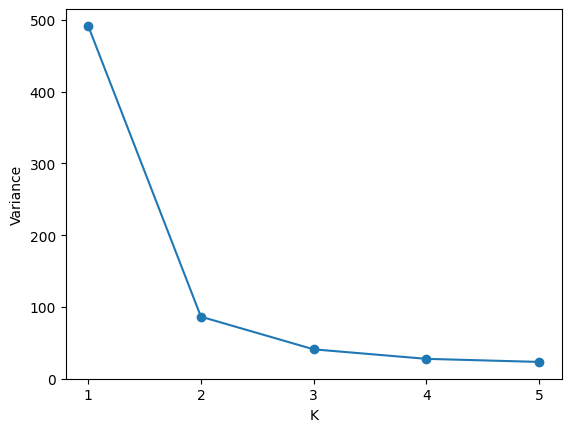

In [9]:
clusterings = []
vars = []
max_K = 5
iters = 5

X = iris[["petal_length", "sepal_width"]].to_numpy()

for K in range(1, max_K + 1):
    clusters, var = kmeans_fit(X, K, iters)
    vars.append(var)
    clusterings.append(clusters)
    
plt.plot(range(1, max_K + 1), vars, marker='o')
plt.xlabel("K")
plt.xticks(range(1, max_K + 1))
plt.ylabel("Variance")
plt.show()